# 01. Exploración de los datos

En este notebook revisamos los datos crudos antes de limpiarlos. La idea es entender qué variables hay, si hay valores faltantes o raros, y qué variables parecen relacionarse con reprobar. Las decisiones que salen de aquí son las que después se programan en `src/datos/limpiar.py`.

Los datos son de 649 estudiantes de portugués de dos escuelas en Portugal (UCI Student Performance). El diccionario completo está en `docs/diccionario_datos.md`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RAIZ = Path("..")
df = pd.read_csv(RAIZ / "data" / "raw" / "estudiantes_portugues.csv")
print("filas y columnas", df.shape)
df.head()

filas y columnas (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## Tipos de variables

Hay 16 variables numéricas y 17 de texto. Varias de las numéricas en realidad son escalas del 1 al 5 (como `goout` o `Dalc`), así que no son medidas continuas, pero sí tienen un orden y por eso las dejamos como números.

In [2]:
print(df.dtypes.value_counts())
df.describe().round(2).T

str      17
int64    16
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


## Valores faltantes y duplicados

In [3]:
print("valores faltantes por columna")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() > 0 else "ninguno")
print("renglones duplicados", df.duplicated().sum())

valores faltantes por columna
ninguno
renglones duplicados 0


El dataset no tiene valores faltantes ni duplicados. Aun así, el script de limpieza sí revisa las dos cosas y además convierte en faltante cualquier valor fuera del rango que dice la documentación (por ejemplo una calificación mayor a 20). Así, si el equipo cambia de archivo o llega una versión nueva de los datos, el pipeline lo detecta y lo reporta en `reports/metrics/limpieza.json`.

## La calificación final y el caso de los ceros

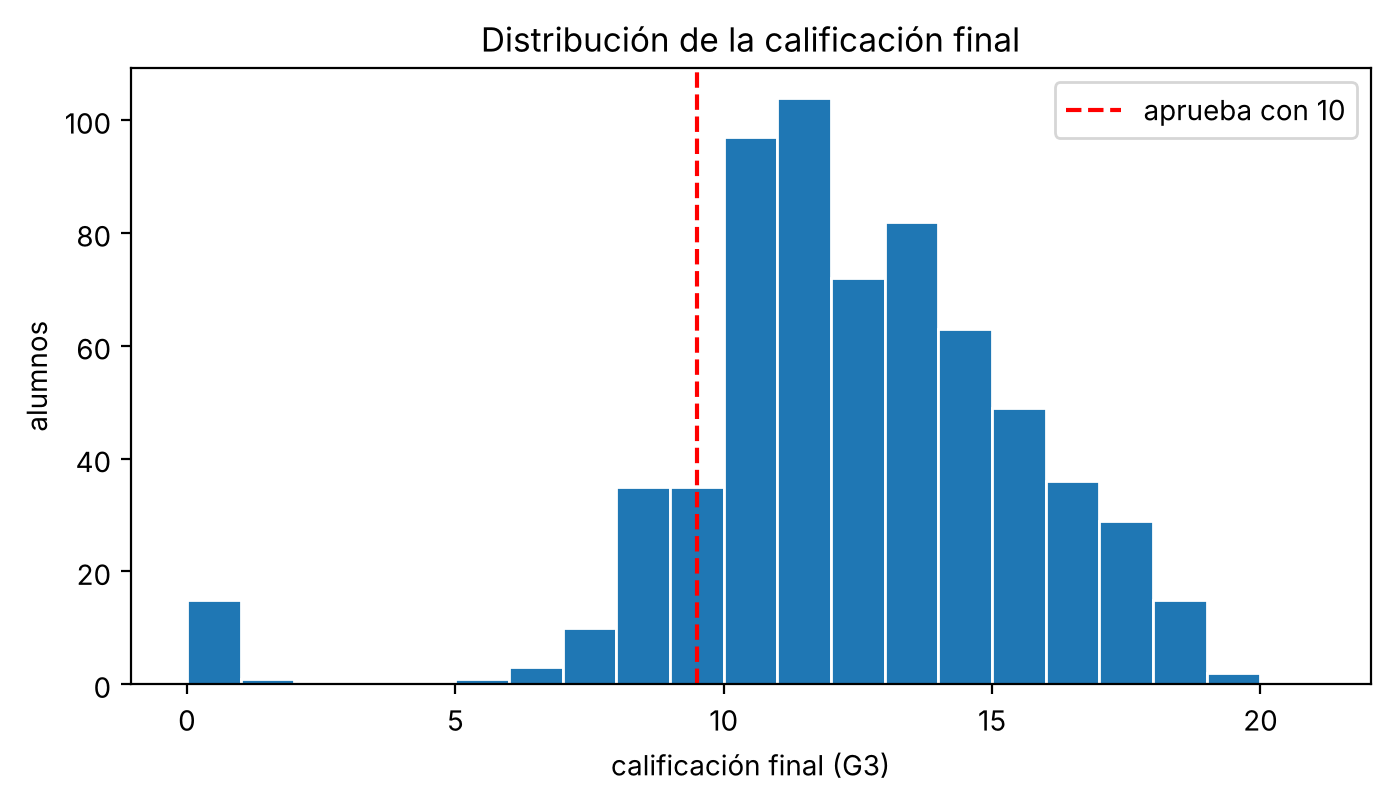

alumnos con G3 = 0 15


,G1,G2,G3,absences,failures
163,11,9,0,0,2
440,7,0,0,0,0
519,8,7,0,0,0
563,7,0,0,0,1
567,4,0,0,0,1
583,8,6,0,0,1
586,8,8,0,0,0
597,9,0,0,0,1
603,5,0,0,0,0
605,5,0,0,0,1


In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["G3"], bins=range(0, 22), edgecolor="white")
ax.axvline(9.5, color="red", ls="--", label="aprueba con 10")
ax.set(xlabel="calificación final (G3)", ylabel="alumnos", title="Distribución de la calificación final")
ax.legend()
plt.show()

print("alumnos con G3 = 0", (df["G3"] == 0).sum())
df[df["G3"] == 0][["G1", "G2", "G3", "absences", "failures"]]

Hay 15 alumnos con calificación final de 0, separados del resto de la distribución. Varios tenían calificaciones normales en los periodos anteriores, así que un 0 no tiene sentido como desempeño real. En este dataset se interpreta como que el alumno no presentó el examen final. Decidimos quitarlos porque es un fenómeno distinto (deserción o ausencia), y si los dejamos, los modelos de calificación aprenderían a predecir ceros que no tienen que ver con lo que estamos estudiando.

## Outliers en las faltas

Q1 = 0.0, Q3 = 6.0, límite superior (IQR) = 15.0
alumnos arriba del límite 21 | máximo 32


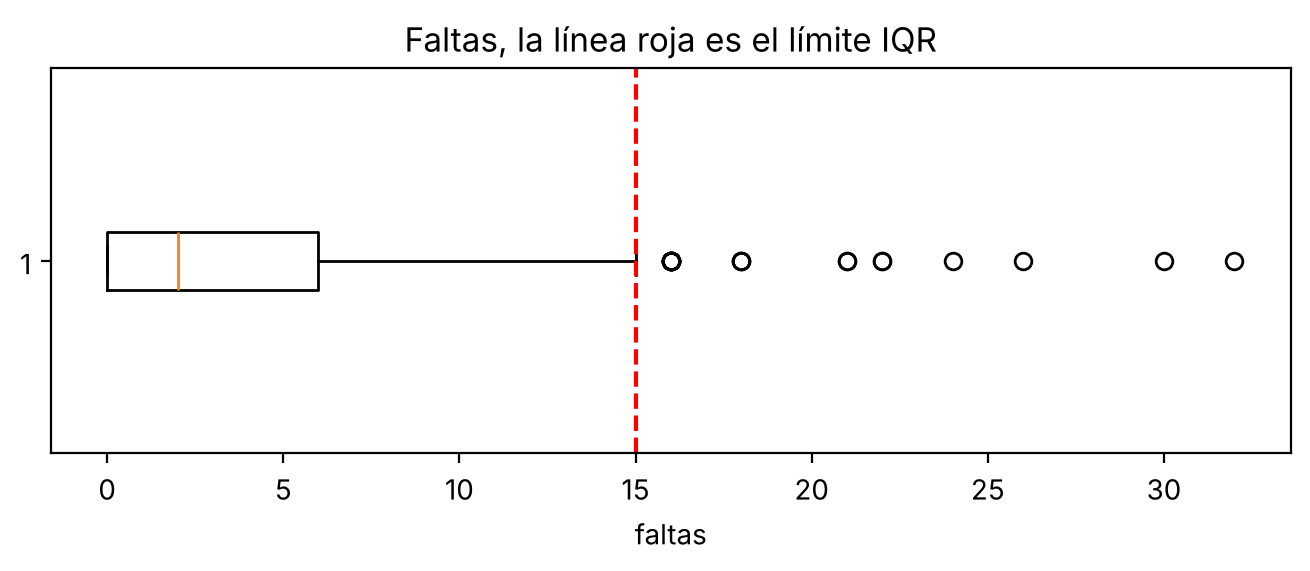

In [5]:
q1, q3 = df["absences"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
print(f"Q1 = {q1}, Q3 = {q3}, límite superior (IQR) = {limite}")
print("alumnos arriba del límite", (df["absences"] > limite).sum(), "| máximo", df["absences"].max())

fig, ax = plt.subplots(figsize=(8, 2.5))
ax.boxplot(df["absences"], orientation="horizontal")
ax.axvline(limite, color="red", ls="--")
ax.set(xlabel="faltas", title="Faltas, la línea roja es el límite IQR")
plt.show()

Las faltas son la única variable continua con valores muy alejados (hasta 32 faltas cuando tres cuartas partes de los alumnos tienen 6 o menos). No las borramos, porque son alumnos reales y faltar mucho puede ser justo una señal de riesgo. Lo que hacemos es recortarlas al límite de 15 faltas (winsorización), para que unos pocos valores extremos no muevan demasiado los coeficientes de la regresión ni los centroides de K-means.

## ¿Qué se relaciona con reprobar?

porcentaje que reprueba (sin los ceros) 13.4 %


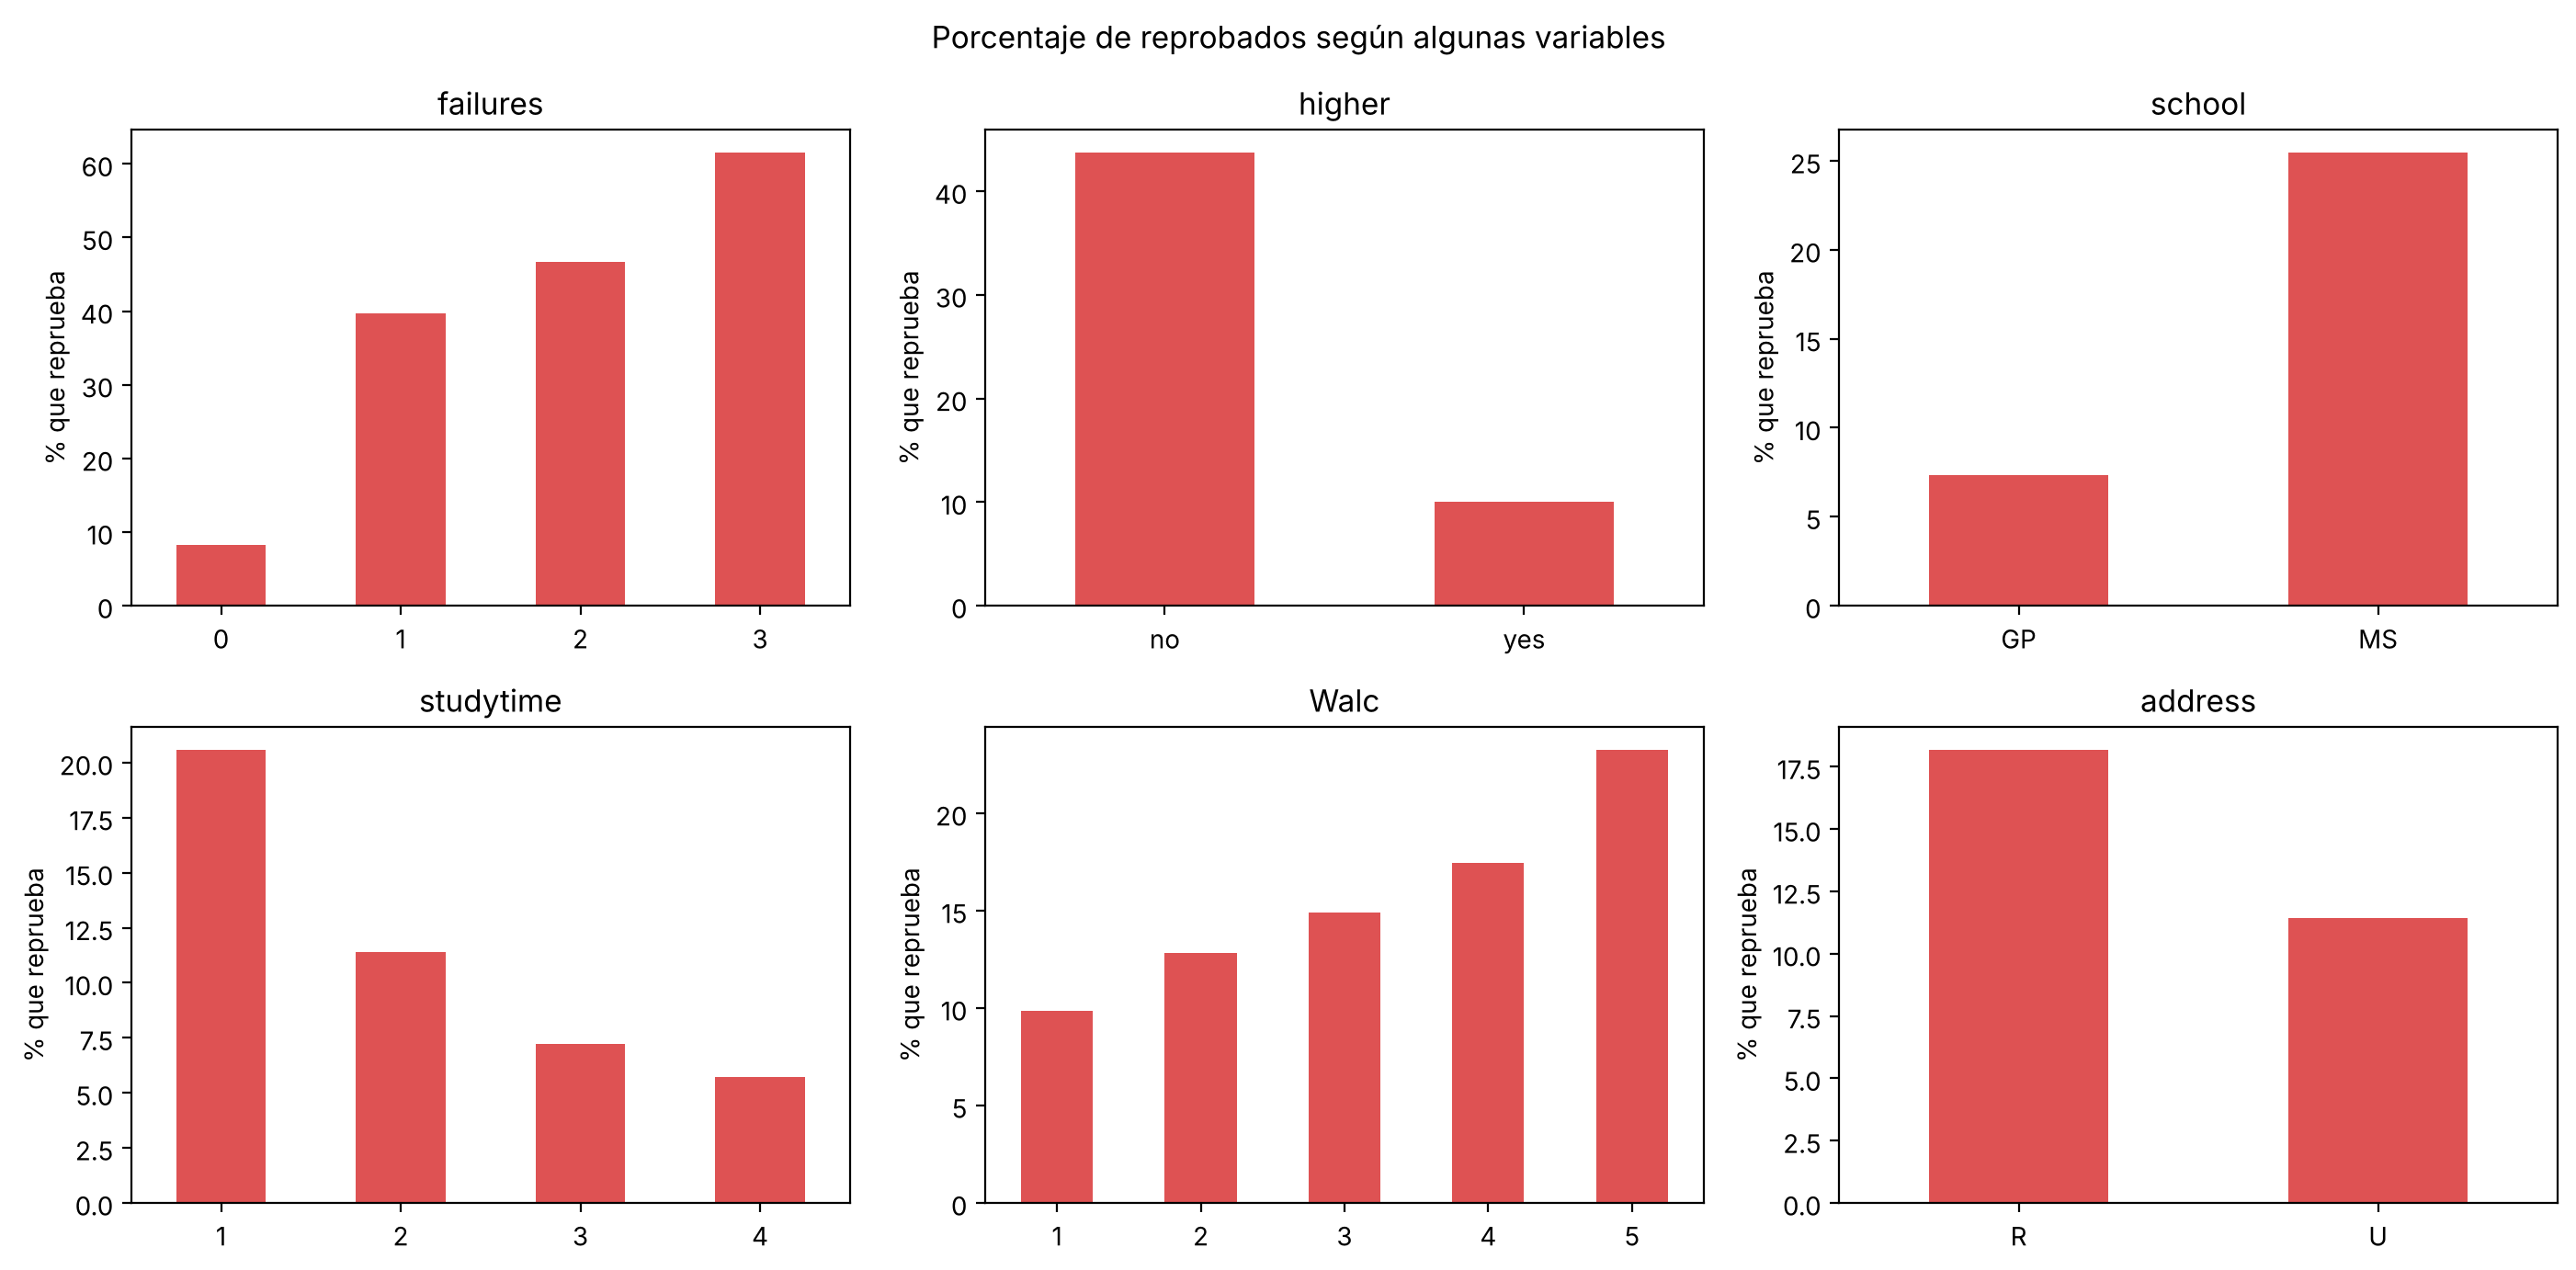

In [6]:
df["reprobado"] = (df["G3"] < 10).astype(int)
datos = df[df["G3"] > 0]
print("porcentaje que reprueba (sin los ceros)", round(datos["reprobado"].mean() * 100, 1), "%")

fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(ejes.flat, ["failures", "higher", "school", "studytime", "Walc", "address"]):
    (datos.groupby(col)["reprobado"].mean() * 100).plot(kind="bar", ax=ax, color="tab:red", alpha=0.8)
    ax.set(title=col, ylabel="% que reprueba", xlabel="")
    ax.tick_params(axis="x", rotation=0)
plt.suptitle("Porcentaje de reprobados según algunas variables")
plt.tight_layout()
plt.show()

Las relaciones más claras son con haber reprobado antes (`failures`) y con querer estudiar la universidad (`higher`). También se ve una diferencia grande entre escuelas, que retomamos en el análisis ético porque puede reflejar desigualdad de recursos más que algo de los alumnos.

Solo 13% de los alumnos reprueba, así que las clases están desbalanceadas. Esto hace que la exactitud engañe (un modelo que diga siempre "aprueba" acertaría 87%), por eso en los modelos de clasificación nos fijamos sobre todo en el recall.

## Correlación entre variables numéricas

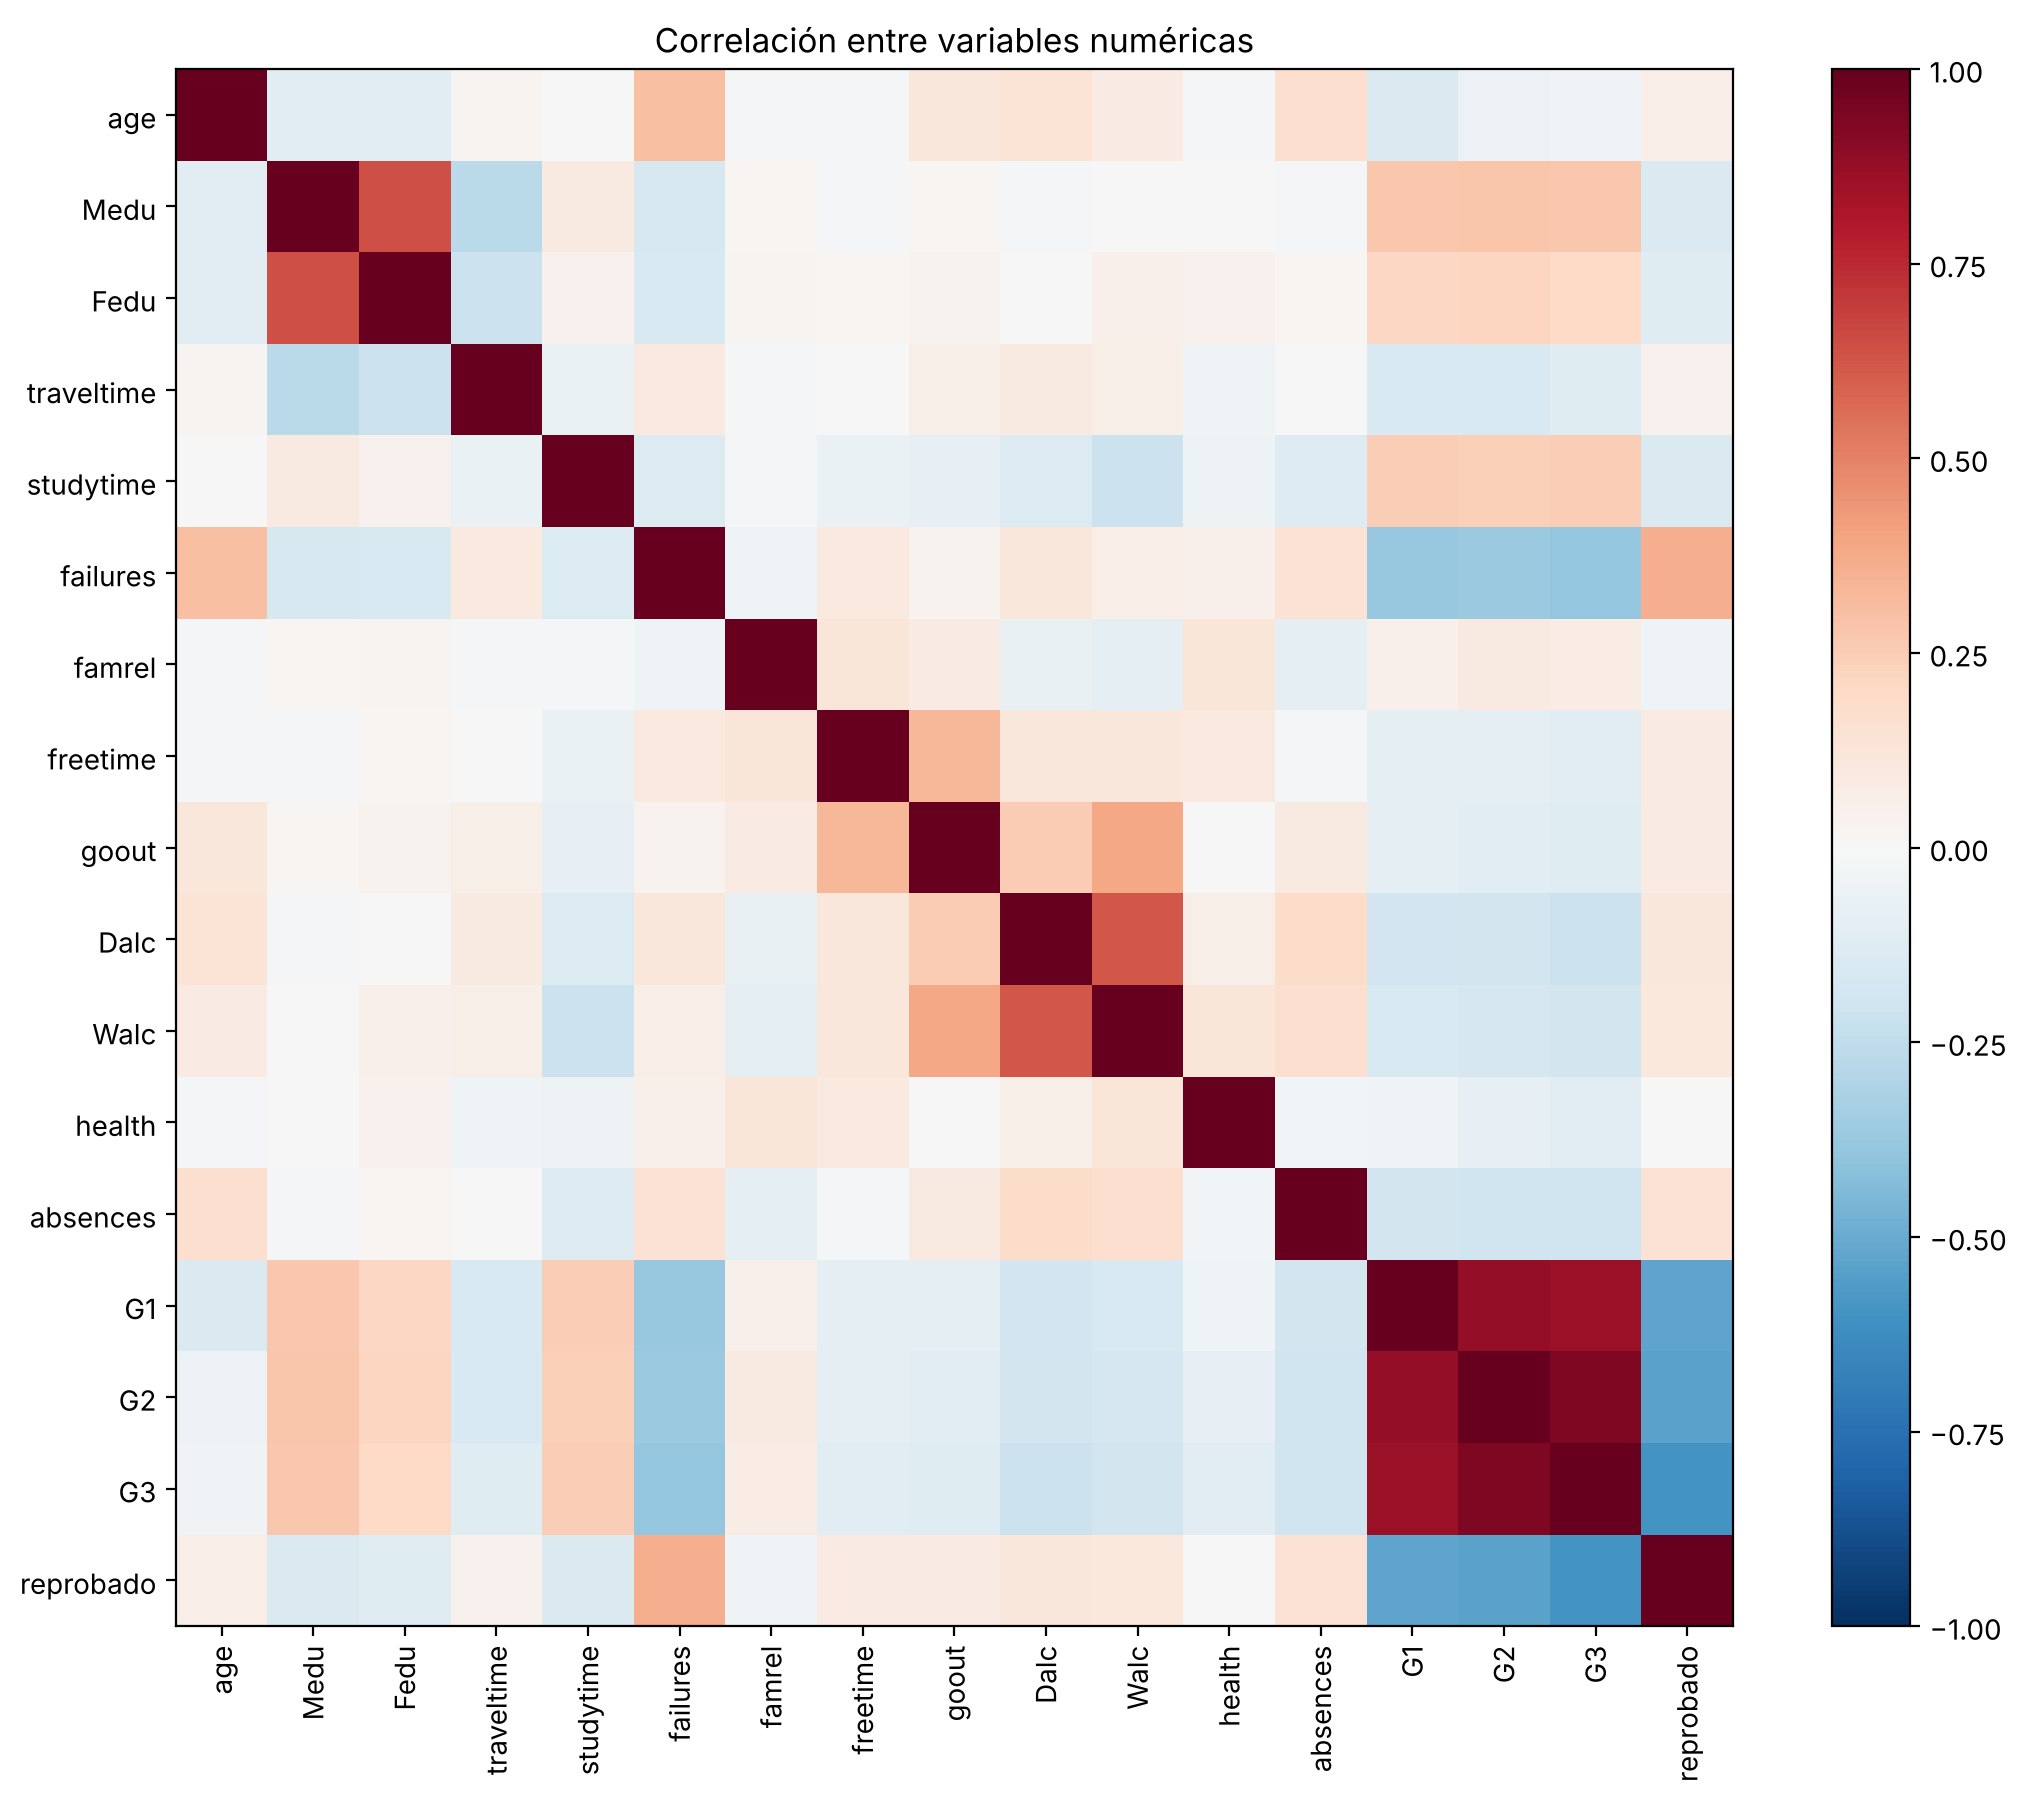

failures     -0.39
Dalc         -0.21
absences     -0.20
Walc         -0.18
traveltime   -0.12
goout        -0.12
freetime     -0.11
health       -0.10
age          -0.04
famrel        0.07
Fedu          0.20
studytime     0.25
Medu          0.27
G1            0.87
G2            0.93
Name: G3, dtype: float64


In [7]:
numericas = datos.select_dtypes(include="number")
corr = numericas.corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
plt.colorbar(im)
ax.set_title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

print(corr["G3"].drop(["G3", "reprobado"]).sort_values().round(2))

G1 y G2 están casi perfectamente correlacionadas con G3 (más de 0.8). Si las usáramos para predecir si alguien reprueba, el modelo sería muy bueno pero no serviría de mucho, porque cuando ya conoces la calificación del segundo periodo, ya sabes casi todo. Por eso los modelos de riesgo (regresión logística y árbol de decisión) no usan ninguna calificación, y la regresión lineal justo mide cuánto aporta conocer G1.

También se ve que `Dalc` y `Walc` están bastante relacionadas entre sí (alcohol entre semana y en fin de semana), igual que `Medu` y `Fedu`. Por eso en los modelos de riesgo juntamos las dos de alcohol en una sola variable con su promedio. Al principio las usamos por separado y el modelo las ponía como contrapeso una de la otra, por ejemplo tomar más entre semana bajaba la probabilidad de reprobar, lo cual no tiene sentido.

## ¿Hace falta normalizar?

In [8]:
rangos = numericas.drop(columns="reprobado").agg(["min", "max"]).T
rangos["rango"] = rangos["max"] - rangos["min"]
rangos.sort_values("rango", ascending=False).head(8)

,min,max,rango
absences,0,32,32
G1,0,19,19
G3,1,19,18
G2,5,19,14
age,15,22,7
Medu,0,4,4
Fedu,0,4,4
freetime,1,5,4


Sí. Las variables están en escalas muy distintas, las faltas van de 0 a 32 y muchas escalas van solo de 1 a 5. La regresión logística (con regularización), la regresión lineal (para comparar coeficientes) y K-means (que usa distancias) necesitan que todas estén en la misma escala, así que usamos `StandardScaler`. El árbol de decisión no lo necesita porque solo compara cada variable con un umbral.

El escalador va dentro de un `Pipeline` en cada modelo, para que aprenda la media y desviación solo con los datos de entrenamiento y no haya fuga de información de los datos de prueba.